# Reconstructing diffusion-weighted EPI

**MRI TogetherThon · Day 2 · 1 December 2026 · Mengye Lyu** · [Program](https://mritogether.esmrmb.org/26m/programbook)

A single-shot echo-planar imaging (EPI) acquisition collects a train of echoes after one excitation. Follow the echoes from the receiver to an image.

- **Nyquist ghost correction.** Estimate the mismatch between forward and reverse readouts from the $b=0$ echoes. Apply that calibration to the higher-b echoes acquired with the same readout.
- **Ramp sampling correction.** Use the readout gradient and sample times to place each complex measurement on a uniform $k_x$ grid.
- **Parallel imaging reconstruction and partial Fourier reconstruction.** Inspect the $k_y$ sampling pattern. Skipped lines inside the measured band and a missing edge require different information to reconstruct.

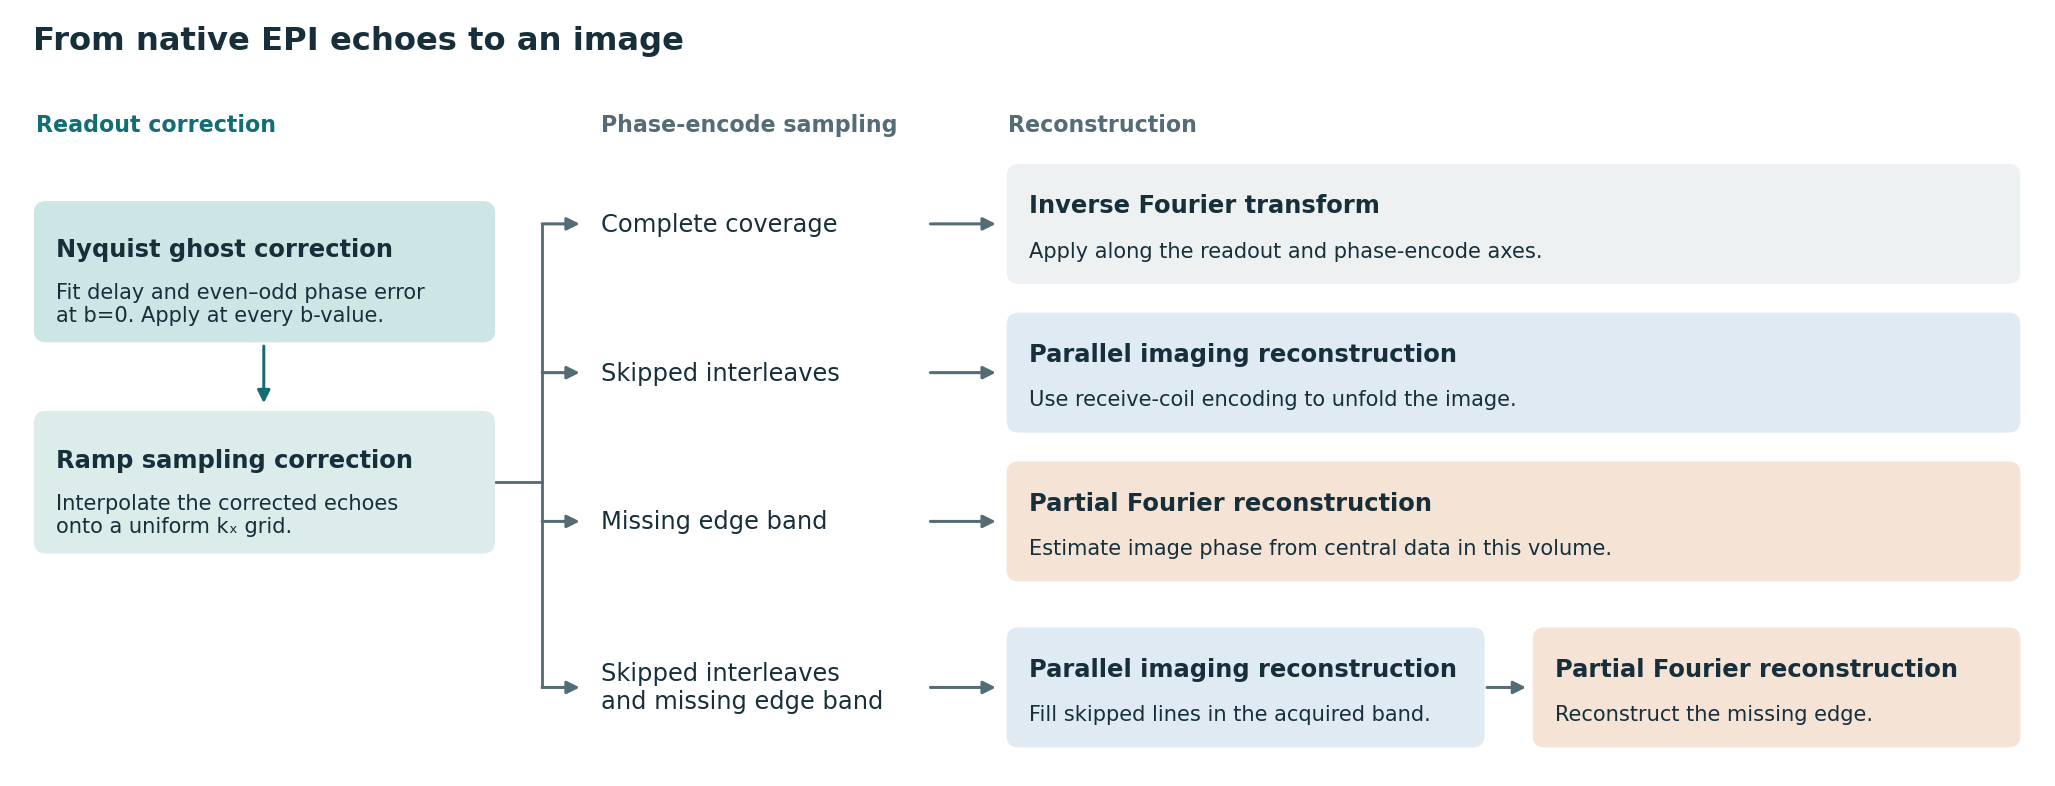

*Follow the bottom path when both patterns are present. Parallel imaging reconstruction fills the skipped lines inside the acquired band. Partial Fourier reconstruction uses the image phase from that volume to estimate the missing edge.*

## What does one EPI echo measure?

- **Diffusion contrast.** For a compartment with diffusivity $D$, the signal magnitude is $A_b=S_0 e^{-bD}$, where $S_0$ is its magnitude in the $b=0$ image. As $b$ increases, a compartment with higher diffusivity loses signal more rapidly. [Stejskal & Tanner, 1965](https://doi.org/10.1063/1.1695690)
- **Image phase.** Motion during diffusion encoding can change the phase $\theta_b(x,y)$. The complex image is $m_b=A_b e^{i\theta_b}$.
- **Spatial encoding.** Sample $j$ of echo $\ell$ measures one spatial frequency of $m_b$. At the k-space origin, signals from the entire slice add with no spatial phase encoding.

$$s_{b,\ell j}=\iint m_b(x,y)\,e^{-i2\pi[k_{x,\ell}(t_j)x+k_{y,\ell}y]}\,dx\,dy.$$

### Follow the readout

- In the imaging train, each readout lobe traces one $k_y$ line. A phase-encode blip selects the next line, and the next readout runs in the opposite direction. [Elster, Echo-planar imaging](https://mriquestions.com/echo-planar-imaging.html)
- Integrating the readout gradient $G_x$ from time $t_a$ gives the distance traveled in $k_x$. With $\bar\gamma$ in Hz/T and $G_x$ in T/m, $k_x$ is in cycles/m.

$$k_x(t)=k_x(t_a)+\bar\gamma\int_{t_a}^{t}G_x(u)\,du.$$

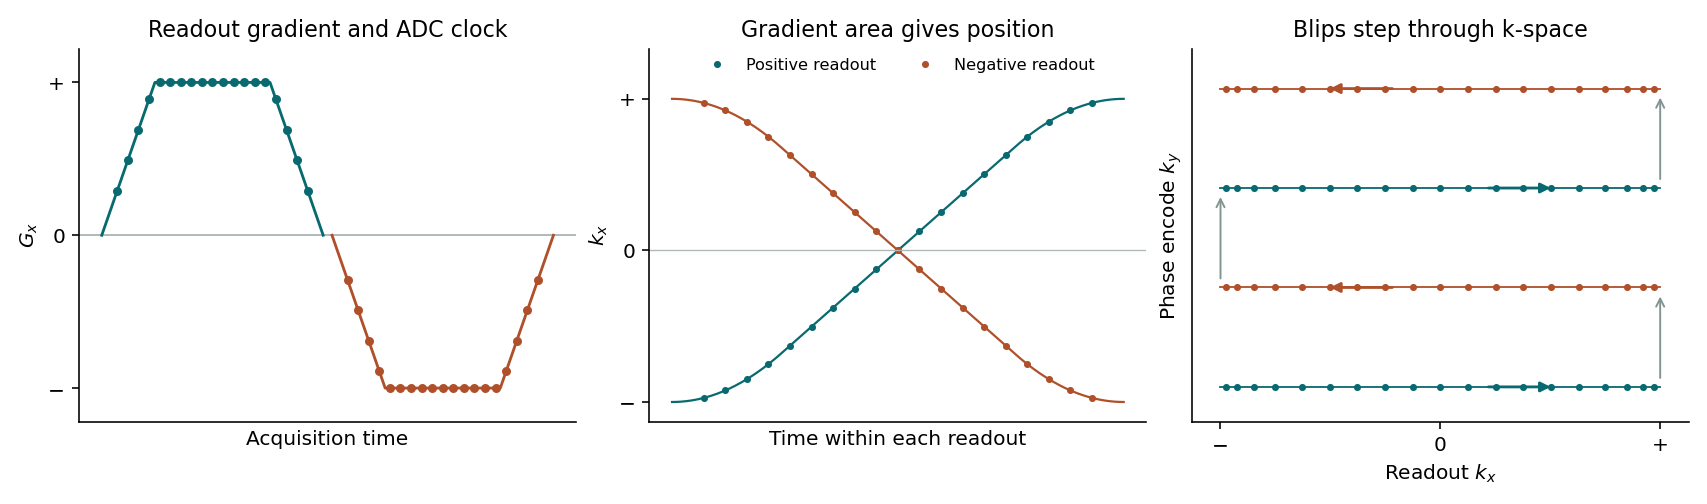

*The receiver samples at equal time intervals. Compare the distance between successive points on the ramp and on the plateau, then follow the next echo in the opposite direction.*

## Nyquist ghosts · Why half the field of view?

- For single-shot EPI with adjacent $k_y$ lines, let $\phi(x)$ be the **even–odd phase error** at readout position $x$. The polarities carry errors $+\phi/2$ and $-\phi/2$ relative to their mean.
- The phase multiplier on echo $\ell$ splits into two terms.

$$
e^{i(-1)^\ell\phi/2}=
\underbrace{\cos(\phi/2)}_{\text{same on all lines}}
+i\underbrace{(-1)^\ell\sin(\phi/2)}_{\text{alternates on successive lines}}.
$$

- **Why half the field of view?** The alternating term repeats every two $k_y$ lines. By the Fourier shift theorem, $(-1)^\ell=e^{-i2\pi\ell/2}$ places its copy half a field of view away along $y$. [Elster, Nyquist ghosts](https://mriquestions.com/nyquist-n2-ghosts.html)
- **How bright is the ghost?** Its amplitude relative to the main component is $|\tan(\phi/2)|$. A small even–odd phase error leaves a faint copy that may overlap the object. [Reeder et al., 1997](https://doi.org/10.1002/mrm.1910380312)

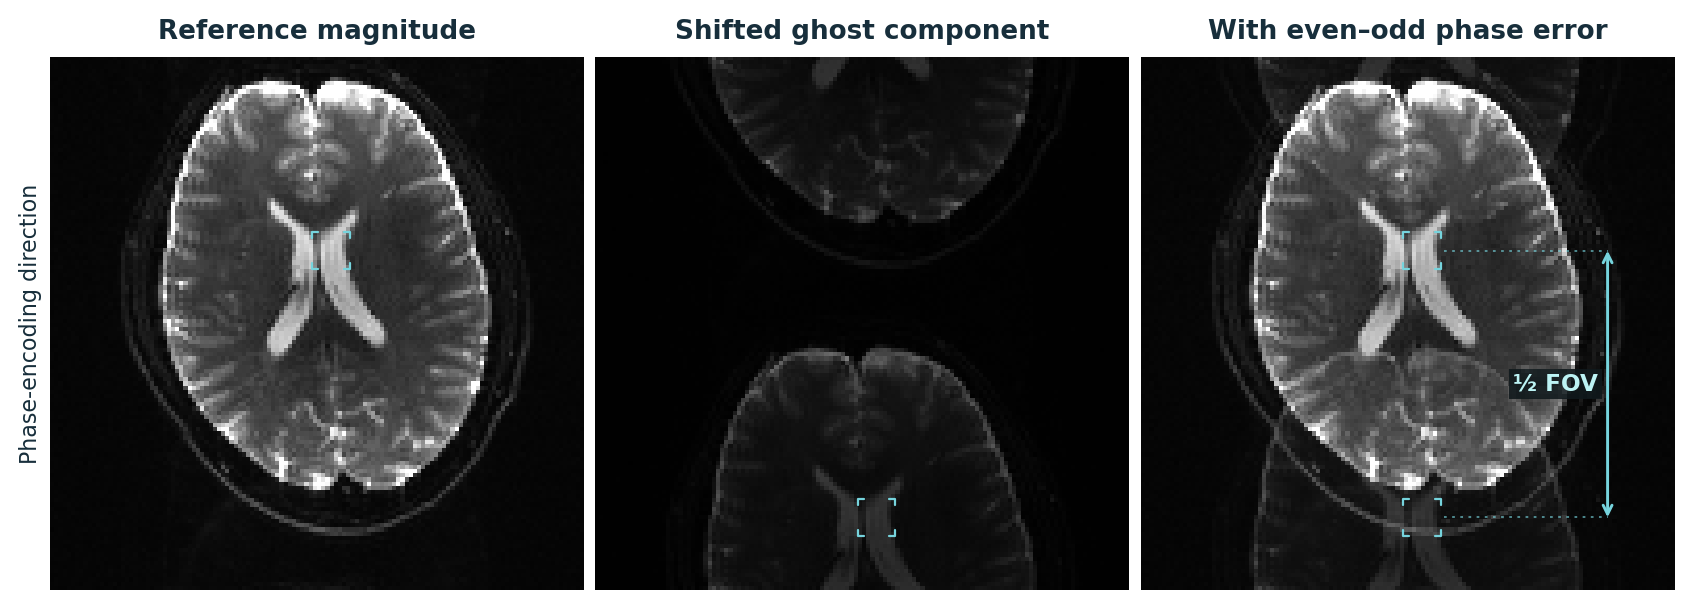

*Find the marked ventricle in the measured image. A modeled even–odd phase error places a faint copy half a field of view away along the phase-encode direction. All three panels share one grayscale window.*

## Fit the readout delay and even–odd phase error at $b=0$

A gradient-to-ADC delay $\tau$ moves a sample from its nominal position $k_x(t)$ to $k_x(t-\tau)$. The displacement is nearly constant on a plateau and changes along a ramp.

$$\delta k_x(t)\simeq-\bar\gamma G_x(t)\tau.$$

| Calibration data | How to find $\tau$ and the constant even–odd phase error $\phi_0$ |
|---|---|
| **Imaging echoes, $b=0$** | Reconstruct trial images $I$ and minimize their energy entropy $-\sum_{j:p_j>0}p_j\log p_j$, where $p_j=\lvert I_j\rvert^2/\sum_l\lvert I_l\rvert^2$. A ghost spreads signal over more pixels. [Skare et al., ISMRM 2006, abstract 2349](https://archive.ismrm.org/2006/2349.html) [McKay et al., 2019](https://doi.org/10.1002/mrm.27563) |
| **Navigator echoes, $b=0$** | Compare opposite-polarity readouts $N_+,N_-$ on the same $k_y$ line. For each trial delay, align their $k_x$ coordinates and estimate $\phi_0=\arg\sum_j N_+(j)N_-^*(j)$. Select the delay with the smallest residual after removing this error. [Heid, ISMRM 1997, p. 2014](https://doi.org/10.1002/mrmp.22419970141) |

When same-polarity navigators bracket an opposite-polarity navigator, their average approximates the signal at its echo time. [Heid, ISMRM 1997, p. 2014](https://doi.org/10.1002/mrmp.22419970141)

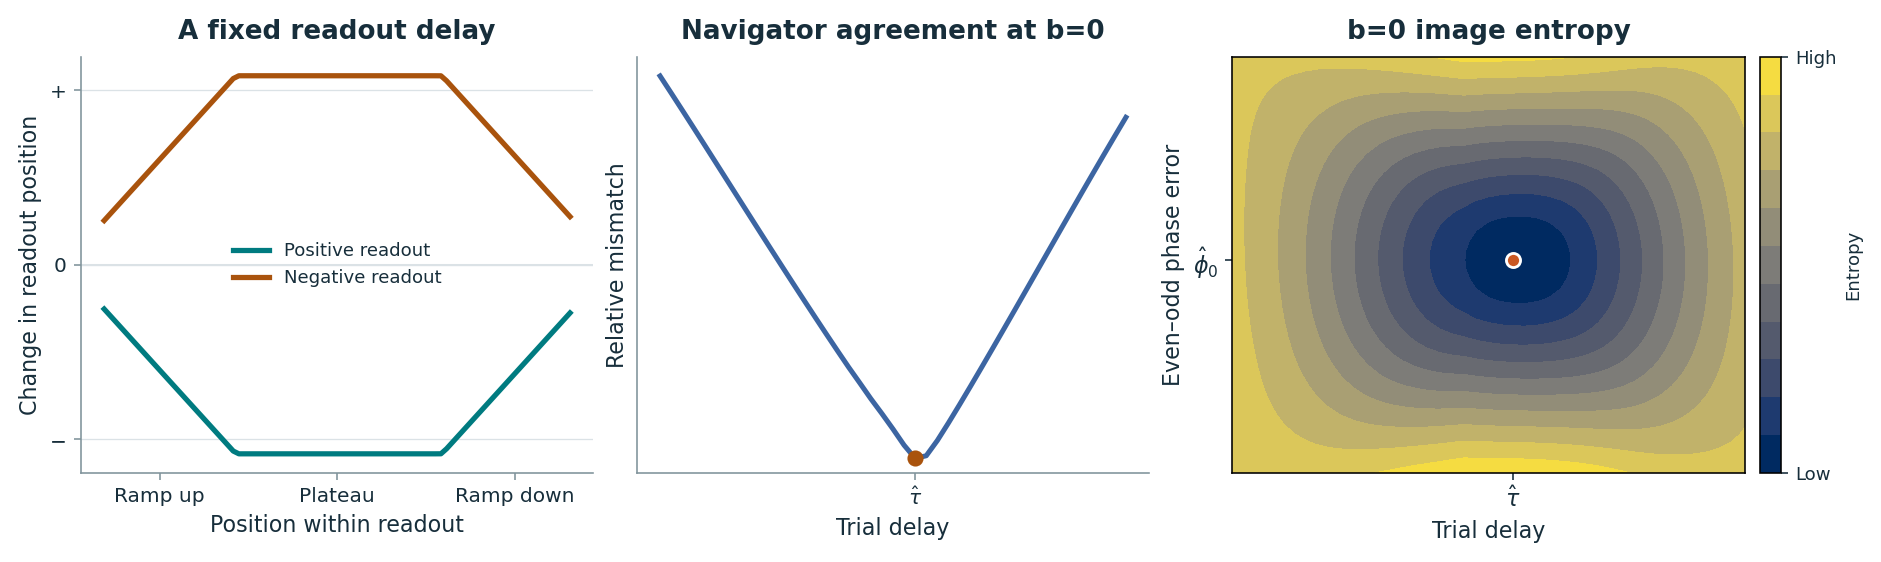

*In this schematic, the navigator fit selects the delay that best aligns opposite-polarity echoes. The imaging-echo fit selects the delay and even–odd phase error that minimize entropy in the baseline image.*

### Transfer the $b=0$ calibration to higher-b DWI

1. **Correct the raw echoes.** For recorded polarity $p=\pm1$, multiply each complex sample by $e^{-ip\hat\phi_0/2}$.
2. **Apply ramp sampling correction.** Assign the sample to $k_x(t-\hat\tau)$ and interpolate onto a uniform readout grid. The coordinate shift depends on sample time. [Nordell et al., ISMRM 2007, abstract 1833](https://cds.ismrm.org/protected/07MProceedings/PDFfiles/01833.pdf)
3. **Reuse both estimates.** Apply the same $(\hat\tau,\hat\phi_0)$ to higher-b volumes with matching geometry and stable timing. This corrects the readout mismatch while preserving each volume’s **image phase**. [Chu et al., 2015](https://doi.org/10.1002/mrm.25527)

Correction after ramp sampling is also possible. Applying the delay at the original sample times accounts for the changing displacement along the ramp.

## Ramp sampling correction

- **Why do spacings change?** The ADC uses a fixed dwell $\Delta t$. During a ramp the gradient changes, so the spacing $\Delta k_x\simeq\bar\gamma G_x(t)\Delta t$ also changes. [Elster, The k-space grid](https://mriquestions.com/k-space-grid.html)
- **Locate each sample.** Evaluate $k_x(t_j-\hat\tau)$ after correcting the readout delay. Sort each position with its complex sample $d'_j$ so that $k_x$ increases.
- **Interpolate onto a uniform grid.** Adjacent Cartesian targets $k_m$ are separated by $1/\mathrm{FOV}_x$. Find the native samples on either side of each target. Use the same weights for real and imaginary components.

$$w=\frac{k_m-k_i}{k_{i+1}-k_i},\qquad K[m,n_\ell]=(1-w)d'_i+w\,d'_{i+1}.$$

- **Place the echo.** The measured $k_y$ gives its grid index $n_\ell$. A two-dimensional inverse Fourier transform gives an image. For a zero-filled preview, set missing locations to zero. [Bruder et al., 1992](https://doi.org/10.1002/mrm.1910230211) · [Nordell et al., 2007](https://cds.ismrm.org/protected/07MProceedings/PDFfiles/01833.pdf)

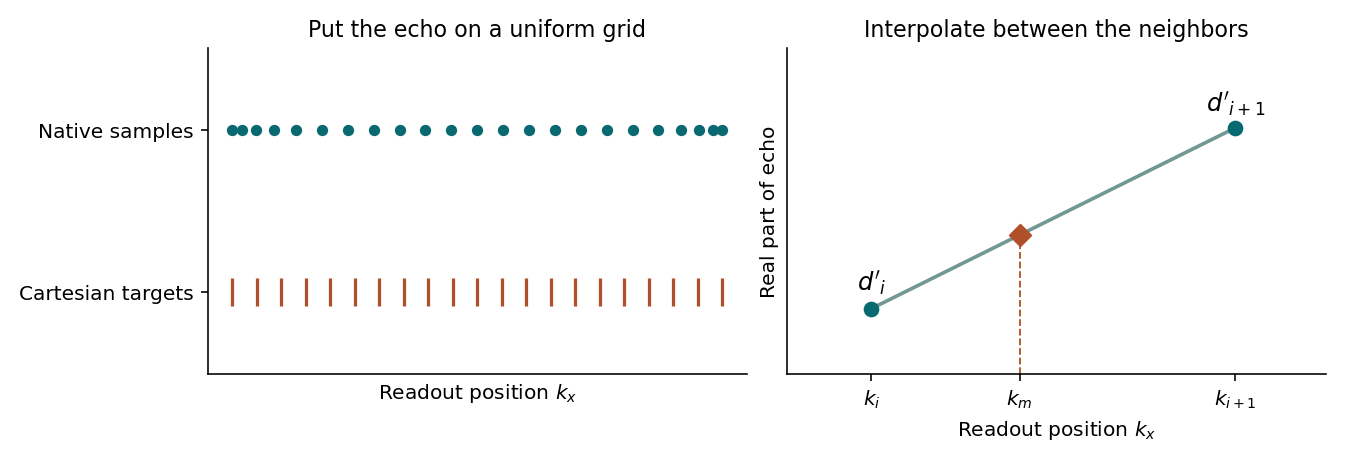

*Ramp sampling places native samples closer together near the ends of the echo. At each Cartesian target, the same two interpolation weights act on the real and imaginary signal.*

## Which phase-encode lines are missing?

- **One edge is missing.** Partial Fourier reconstruction uses the image phase estimated from the same volume’s central lines.
- **Interleaves are missing.** Parallel imaging reconstruction uses the different spatial sensitivities of the coils. SENSE uses coil maps to unfold the image. GRAPPA uses calibration lines to learn how neighboring coil samples predict a missing sample. [Pruessmann et al., 1999](https://pubmed.ncbi.nlm.nih.gov/10542355/) · [Griswold et al., 2002](https://doi.org/10.1002/mrm.10171)
- **Both patterns are present.** Fill the skipped interior lines with parallel imaging reconstruction. Estimate image phase from the center of the completed band, then use partial Fourier reconstruction to recover the missing edge.

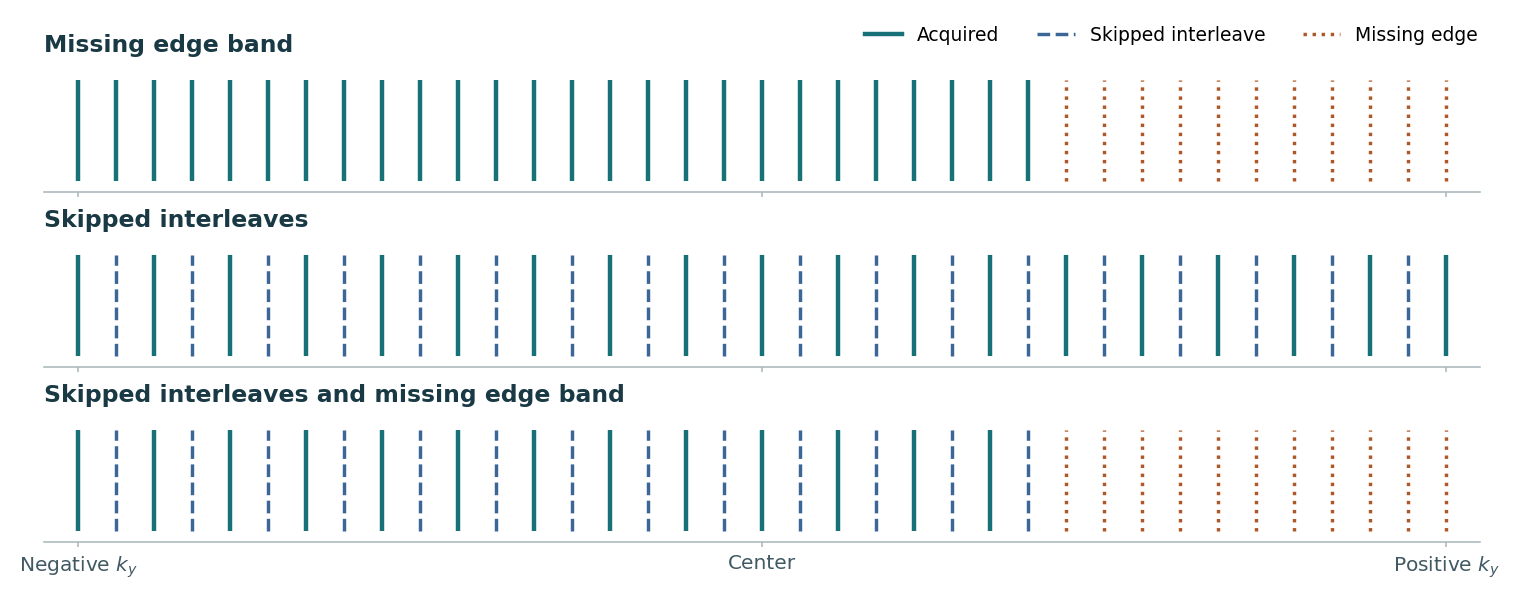

*In the bottom mask, the blue gaps have acquired neighbors on both sides. The orange gaps extend to the edge of k-space. Which gap can the coil calibration fill?*

## Partial Fourier reconstruction begins with a conjugate pair

- **Real image.** Opposite points in k-space satisfy $K(-k_x,-k_y)=K(k_x,k_y)^*$. Changing the signs of both coordinates preserves the real component and reverses the imaginary component.
- **Complex diffusion image.** Image phase generally breaks that exact symmetry. Copying the conjugate partner can then give the wrong signal.
- **Why acquire past the center?** The measured overlap around the origin supplies a low-resolution estimate of the image phase. Partial Fourier reconstruction uses this estimate to recover detail from the missing side. [Elster, Partial Fourier techniques](https://mriquestions.com/partial-fourier.html) · [Feinberg et al., 1986](https://doi.org/10.1148/radiology.161.2.3763926) · [MacFall et al., 1988](https://doi.org/10.1016/0730-725X%2888%2990444-4)

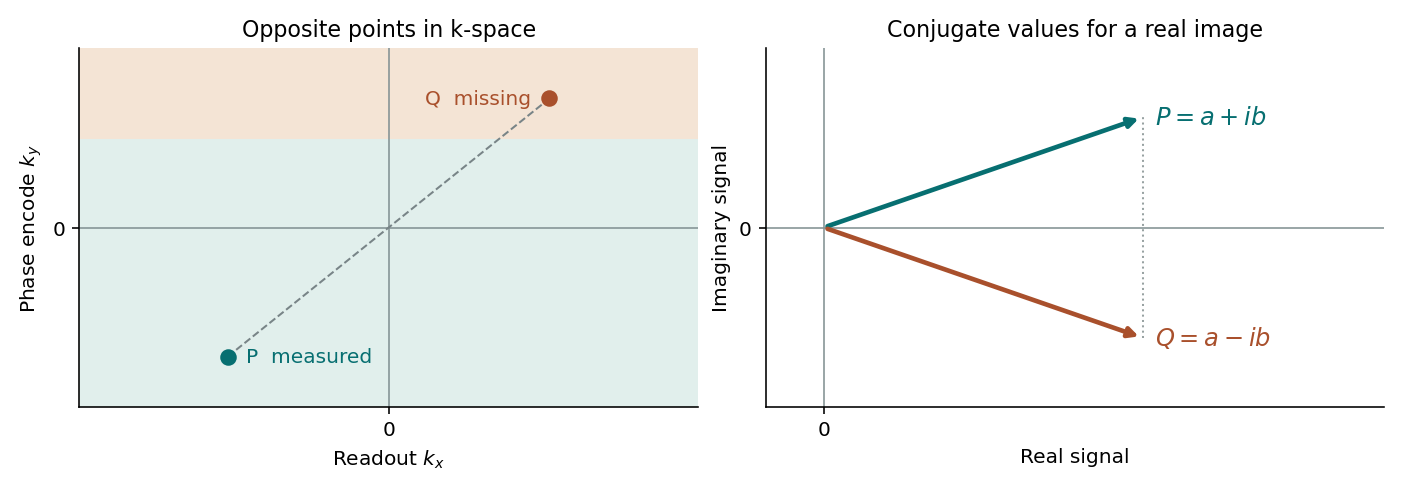

*For a real image, reflecting through the k-space origin preserves the real component and reverses the sign of the imaginary component.*

## Partial Fourier reconstruction · Homodyne

- **What does zero filling do?** Truncating one edge of $k_y$ blurs sharp transitions and can cause ringing along the phase-encoding direction.
- **Estimate image phase for each volume.** Select a central band $L$ within the symmetric overlap. Its low-resolution image gives the smooth phase estimate $\hat\theta_b=\arg\mathcal F^{-1}(L K_b)$.
- **Weight and project.** Homodyne weights $W$ emphasize frequencies with missing partners. Project the weighted complex image onto its estimated image-phase axis to obtain a signed real amplitude. [Noll et al., 1991](https://doi.org/10.1109/42.79473)

$$\hat A_b=\operatorname{Re}\!\left[e^{-i\hat\theta_b}\,\mathcal F^{-1}(W K_b)\right].$$

- **Predict the signal loss.** An image-phase mismatch $\delta$ leaves a fraction $\cos\delta$ of the voxel’s amplitude. Estimate the axis again in the higher-b image.

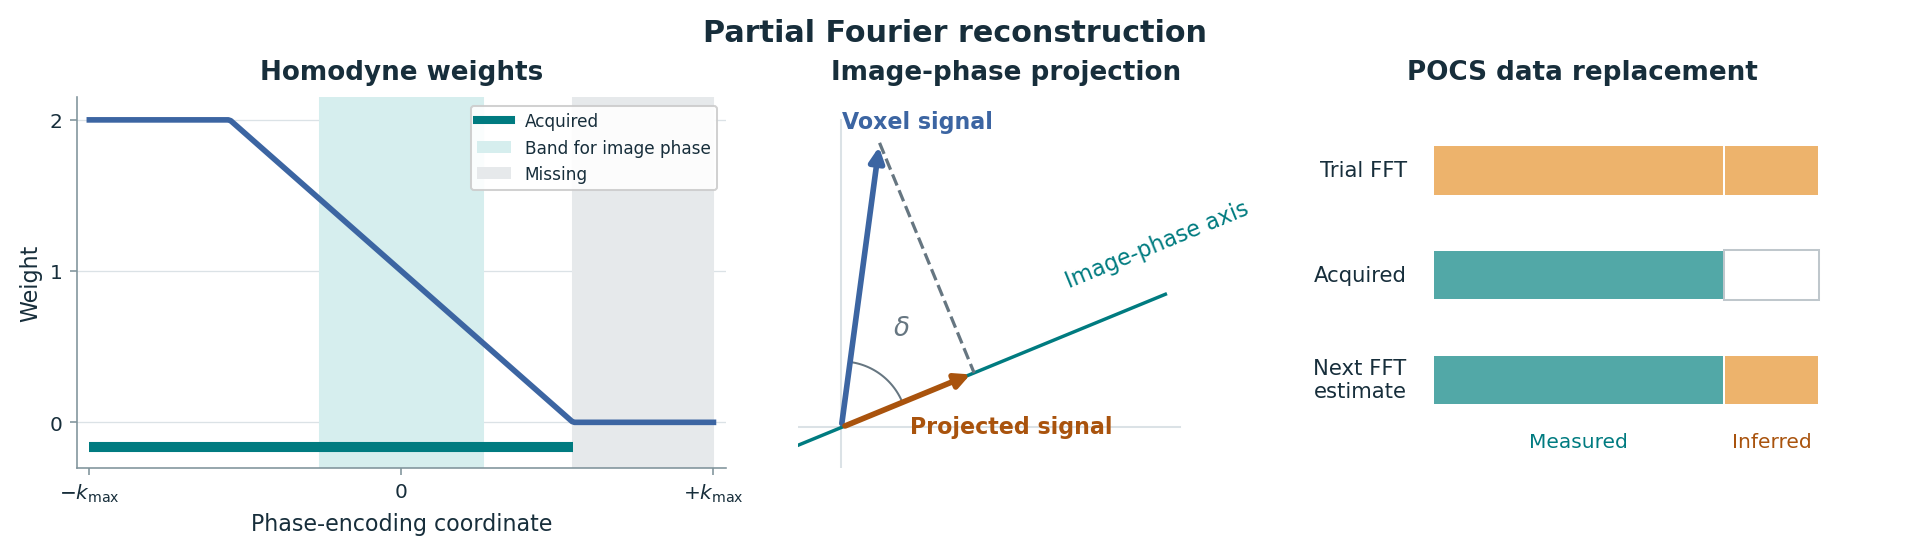

*Homodyne projects the weighted image onto its estimated image-phase axis. POCS restores measured complex samples on each iteration.*

### Partial Fourier reconstruction · POCS

The method of projections onto convex sets (POCS) alternates an image-phase constraint with a measured-data constraint. Start with the zero-filled image $m^{(0)}=\mathcal F^{-1}K_b$. Use the **same volume's image-phase estimate** $q_b=e^{i\hat\theta_b}$ and acquisition mask $M$. Repeat two projections. [Cuppen & van Est, 1987](https://doi.org/10.1016/0730-725X%2887%2990402-4) [Haacke et al., 1991](https://doi.org/10.1016/0022-2364%2891%2990253-P)

1. **Image domain.** Keep the component of each voxel along its estimated image-phase axis using $u^{(n)}=q_b\operatorname{Re}(q_b^*m^{(n)})$.
2. **Fourier domain.** Keep predictions where data are missing. Restore the measured **complex** samples with $K^{(n+1)}=M K_b+(1-M)\mathcal F u^{(n)}$.

Inverse transform and repeat. On the final iteration, the measured frequencies match the data. The inferred frequencies still depend on the image-phase estimate.

## Multishot diffusion EPI · unfold each shot, then combine

- **Why reconstruct shots separately?** Motion can give each shot a different image phase, $I_s=Ae^{i\psi_s}$. Merging inconsistent shots in k-space can produce ghosts.
- **Model each shot.** Receive coil $c$ measures $d_{s,c}=P_s\mathcal F(C_c I_s)+\epsilon_{s,c}$, where $P_s$ selects the shot's samples and $C_c$ is the coil sensitivity.
- **Parallel imaging reconstruction.** Estimate $C_c$ from matched multicoil calibration data. To unfold each shot, solve the regularized sensitivity-encoding problem

$$\hat I_s=\arg\min_I\sum_c\|P_s\mathcal F(C_c I)-d_{s,c}\|_2^2+\lambda\|I\|_2^2.$$

- **Combine magnitudes across shots.** $I_{\rm rSOS}=\sqrt{\sum_s|\hat I_s|^2}$. The different shot phases disappear in the magnitude combination. [Skare et al., 2007](https://doi.org/10.1002/mrm.21176) · [Uecker et al., 2014](https://doi.org/10.1002/mrm.24751)

# Hands-on · Reconstruct a single-shot diffusion EPI acquisition

Run the Python cells in order from the workshop folder. The complex echoes, gradients and acquisition labels are bundled with the notebook. [Workshop environment](https://mcencini.github.io/mritogetherthon/) · [BART](https://mrirecon.codeberg.page/)

## 1 · Read the echo train

- **Acquisition.** Start with the supplied `b0-500` spin-echo EPI series. The b=0 and b=500 s/mm² (x direction) files share a TE of 46.7 ms, a 240 × 120 mm field of view and a 128 × 64 reconstruction grid.
- **Signal.** The sequence supplies the ADC times, gradient waveform and spatial frequencies. The complex Shepp–Logan phantom supplies the diffusion contrast and smooth higher-b image phase. Its known image gives us a reference for each reconstruction. [Shepp & Logan, 1974](https://doi.org/10.1109/TNS.1974.6499235) · [scikit-image phantom](https://scikit-image.org/docs/stable/api/skimage.data.html#skimage.data.shepp_logan_phantom)
- **Identify the echoes.** Three unencoded navigators precede the refocusing pulse. Their readout signs are +, −, +. The first imaging echo starts at + again. Continuing the navigator sign count into the image would reverse every imaging polarity.

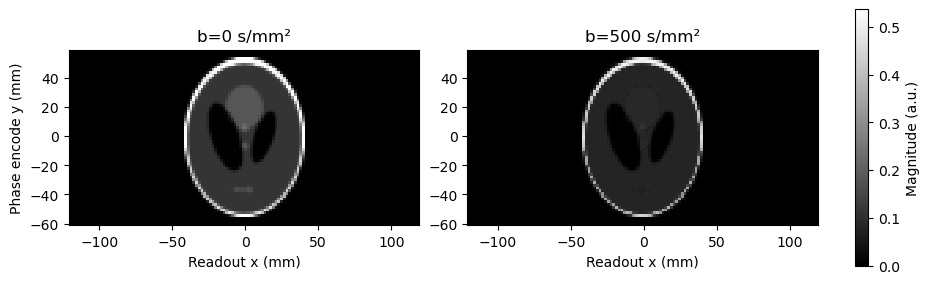

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import epi_recon as epi
import epi_plots as plots
import seq_figures as sequence
from bart_io import bart
from epi_recon import fft2c, ifft2c, pf_phase

scan = epi.load_arrays('data/sequence_dwi.npz')
baseline, diffusion = scan['raw']               # imaging echoes only
kx_grid = epi.cartesian_kx(scan)
ky, ny = scan['ky_idx'], int(scan['matrix_xy'][1])
plots.show_phantom_reference(scan)
plt.show()

The two reference images share one magnitude scale. The bright shell and interior compartments lose different amounts of signal at b=500. The readout runs horizontally and phase encoding vertically. The following plot shows where each echo samples that field of view.

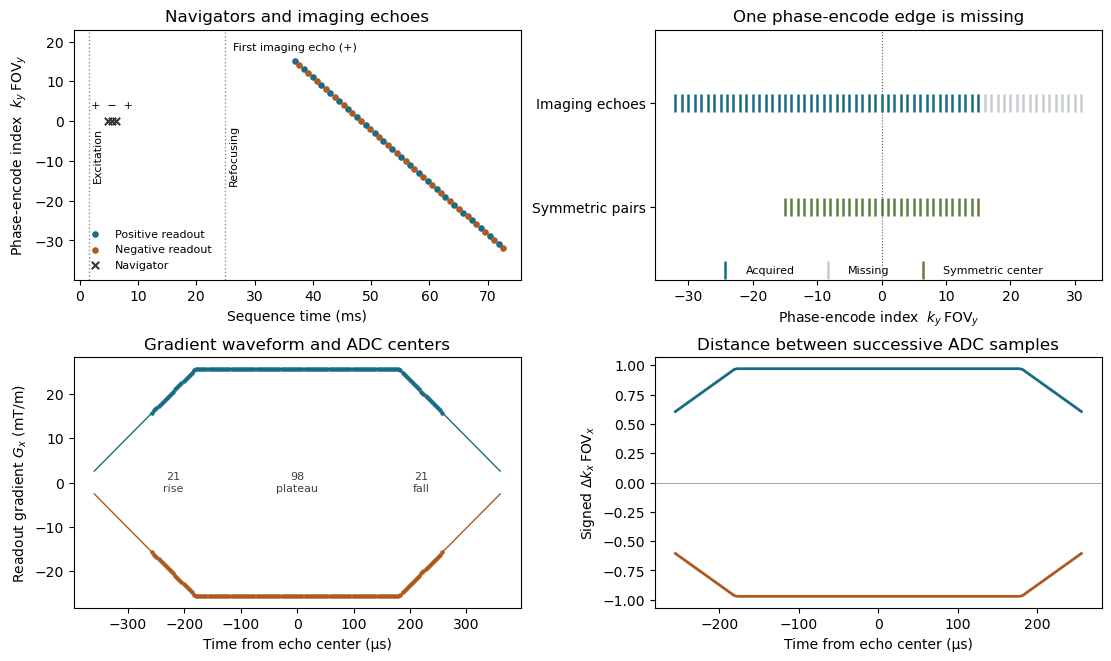

In [2]:
sequence.show_acquisition(scan)
plt.show()

Each imaging echo has 140 samples. In either readout direction, 21 sample centers fall on the leading ramp, 98 on the plateau and 21 on the trailing ramp. The imaging lines run from grid index 47 down to 0. The 16 missing lines are all at the positive phase-encode edge.

**Calibrate the bipolar readout on b=0.** The phantom echoes include a modeled 2.70 µs readout delay and a 0.72 rad even–odd phase error. Use only the baseline imaging echoes to estimate both from image entropy. Then use the recorded polarity to choose the sign of the correction on each echo. [Skare et al., 2006](https://archive.ismrm.org/2006/2349.html) · [Self-referenced implementation](https://github.com/mylyu/pymrghost/blob/main/nyquist_ghost_correction.ipynb)

In [3]:
delay_us, phase_error_rad = epi.fit_b0(baseline, scan)
kx = epi.adc_trajectory(scan, delay_us)
undo_error = np.exp(-0.5j * scan['pol'][:, None] * phase_error_rad)
print(f'b=0 fit: delay {delay_us:.2f} µs, even–odd phase error {phase_error_rad:.3f} rad')

b=0 fit: delay 2.82 µs, even–odd phase error 0.745 rad


**Apply ramp sampling correction.** Start with the central $k_y$ line. Rotate its complex samples using the b=0 fit, sort by delay-adjusted $k_x$, and interpolate onto the Cartesian grid. Check that assembling every echo gives the same central line. [Nordell et al., 2007](https://cds.ismrm.org/protected/07MProceedings/PDFfiles/01833.pdf)

In [4]:
echo = np.flatnonzero(ky == ny // 2)[0]
order = np.argsort(kx[echo])
samples = baseline[echo] * undo_error[echo]
one_line = np.interp(kx_grid, kx[echo, order], samples[order], left=0, right=0)

corrected = [epi.regrid(raw * undo_error, kx, kx_grid, ky, ny) for raw in (baseline, diffusion)]
np.testing.assert_allclose(corrected[0][:, ny // 2], one_line)

**Find the half-FOV ghost.** The images show the central 120 mm along readout and the full phase-encode field of view. Both columns use the acquired lines and zero-fill the missing edge. The orange region marks the expected ghost outside the object. Compare its mean magnitude with the mean in the cyan object region, first at b=0 and then at b=500. BART’s inverse transform uses bitmask 3 for the two image axes.

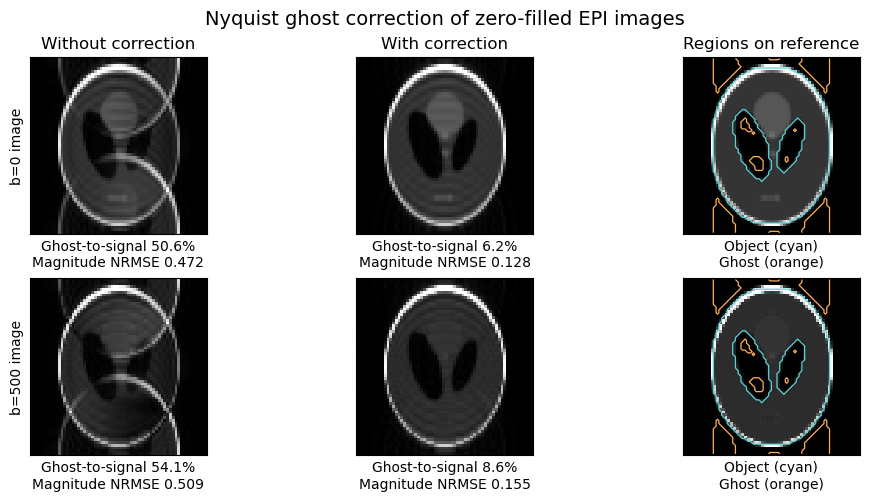

In [5]:
nominal_kx = epi.adc_trajectory(scan)
uncorrected = [epi.regrid(raw, nominal_kx, kx_grid, ky, ny) for raw in (baseline, diffusion)]
before = [bart(['fft', '-iu', '3'], k) for k in uncorrected]
zero_fill = [bart(['fft', '-iu', '3'], k) for k in corrected]
plots.show_correction(before, zero_fill, scan)

## 2 · Recover the missing phase-encode edge

**Partial Fourier reconstruction by homodyne.** Build the mask from the recorded imaging lines. BART receives the acquired fraction, $48/64=3/4$, and the phase-encode axis, 1. Each call estimates a low-resolution image phase from that volume’s central data. [Noll et al., 1991](https://doi.org/10.1109/42.79473) · [BART homodyne example](https://github.com/mrirecon/bart/blob/master/tests/homodyne.mk)

In [6]:
acquired = np.isin(np.arange(ny), ky)
fraction = acquired.mean()
homodyne = [bart(['homodyne', '-C', '1', str(fraction)], k).real for k in corrected]

**Partial Fourier reconstruction by POCS.** Trace one iteration in the function below. In image space, multiplying by $q^*$ and taking the real part projects each voxel onto its estimated phase axis. In k-space, `updated[:, acquired] = kspace[:, acquired]` restores the measured values. Only the missing lines keep their predictions.

In [7]:
def pocs(kspace, acquired, q, iterations=24):
    image = ifft2c(kspace)
    for _ in range(iterations):
        phase_projected = q * (q.conj() * image).real
        updated = fft2c(phase_projected)
        updated[:, acquired] = kspace[:, acquired]
        image = ifft2c(updated)
    return image

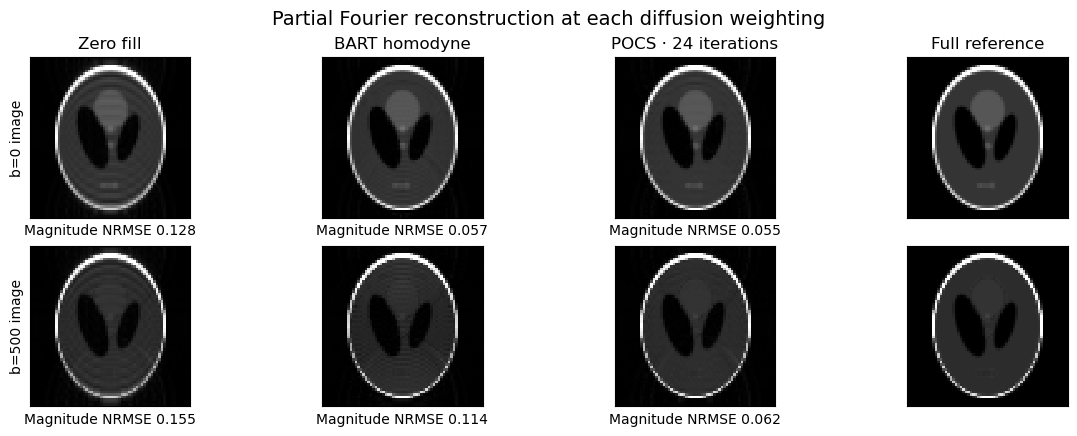

Largest change on a measured higher-b sample after POCS: 2.48e-16


In [8]:
phases = [pf_phase(k, acquired) for k in corrected]
pocs_images = [pocs(k, acquired, q) for k, q in zip(corrected, phases)]
plots.show_partial(zero_fill, homodyne, pocs_images, scan)
residual = fft2c(pocs_images[1])[:, acquired] - corrected[1][:, acquired]
print(f'Largest change on a measured higher-b sample after POCS: {np.max(np.abs(residual)):.2e}')

The fully sampled reference contains the phantom’s prescribed complex image. Magnitude NRMSE compares each reconstruction with its magnitude. The printed residual tests how closely POCS preserves the **acquired complex samples**. These measures answer different questions.

**Which calibration transfers?** Reconstruct the b=500 data again, this time substituting the b=0 image phase in POCS. Both images below use identical measured echoes and the same b=0 readout correction. Compare the inferred edge and the magnitude error.

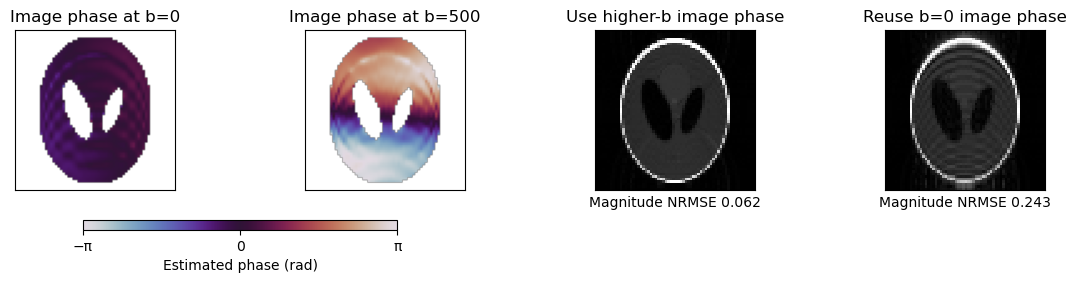

In [9]:
borrowed_phase = pocs(corrected[1], acquired, phases[0])
plots.show_phase_transfer(phases, pocs_images[1], borrowed_phase, scan)
plt.show()

### Omit one step at a time

- **Nyquist ghost correction.** Set the fitted delay and even–odd phase error to zero. Look half a field of view away from the object.
- **Ramp sampling correction.** Treat the native samples as uniformly spaced between the same endpoints. Keep the fitted phase rotation and the delay-induced displacement. Follow the bright rim along the readout direction.
- **Partial Fourier reconstruction.** Zero-fill the missing edge. Look for changes along phase encoding. The supplied phantom acquisition has contiguous lines inside the acquired band.

Every column uses the same echoes and noise. The complete reconstruction uses homodyne. Within each b-value, the grayscale window and the regions used to measure ghost-to-signal ratio are fixed.

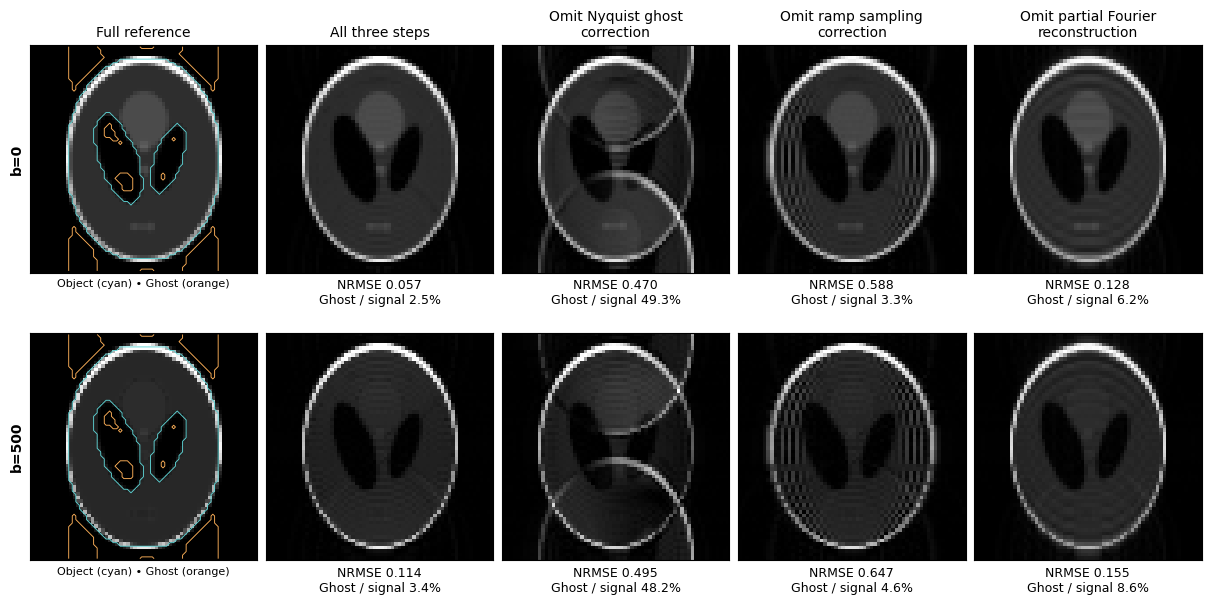

In [10]:
omitted = sequence.omission_images(scan, delay_us, phase_error_rad, uncorrected, zero_fill)
sequence.show_omissions(scan, homodyne, omitted)
plt.show()

Omitting Nyquist ghost correction sends signal into the orange ghost region at both diffusion weightings. Omitting ramp sampling correction broadens and misplaces the bright rim. Omitting partial Fourier reconstruction changes the finer boundaries. The profiles below show the magnitude along a readout line through the phantom.

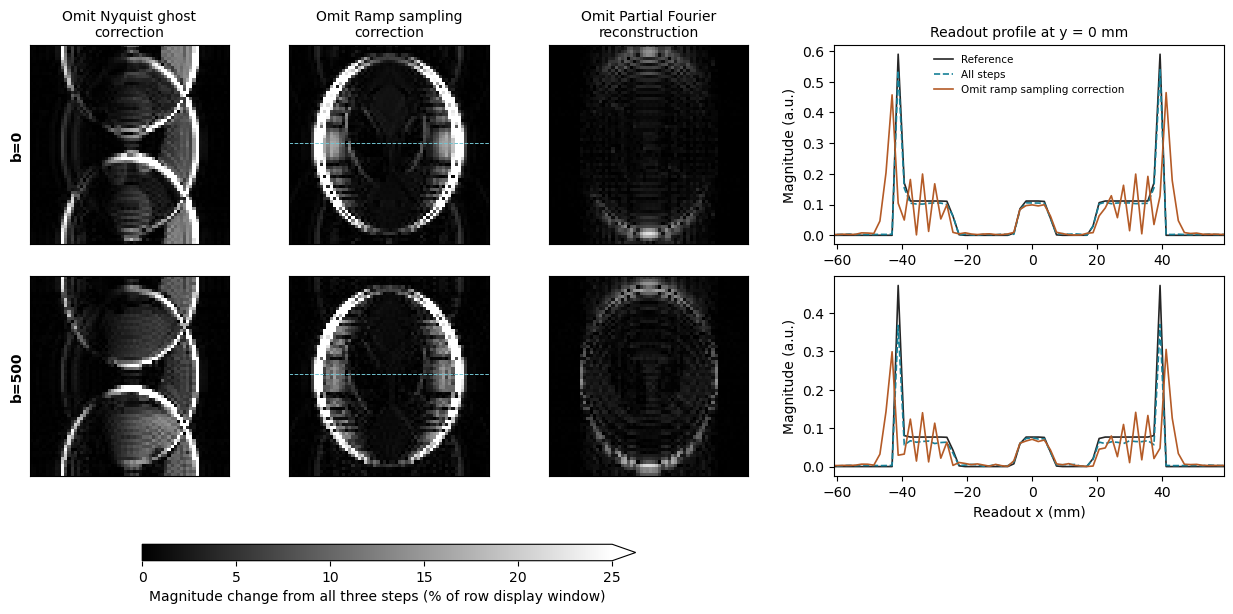

In [11]:
sequence.show_omission_changes(scan, homodyne, omitted)
plt.show()

## 3 · Reconstruct a slice of real brain EPI/DWI data

- **Acquisition.** The same slice was acquired at $b=0$ and $b=1000\ \mathrm{s/mm^2}$ with 32 receive coils. Each volume was collected in one shot.
- **Phase encoding.** The scanner measured lines $0,2,\ldots,126$ on a 128-line grid. A separate calibration acquisition covers the central lines 32–95 without skips.
- **Readout trajectory.** The scanner header specifies the gradient ramps and plateau, the ADC start time and dwell, and the readout field of view. These values determine the nominal trapezoid and the $k_x$ positions of the samples. The waveform below is inferred from the header. [twixtools trajectory calculation](https://github.com/pehses/twixtools/blob/master/twixtools/recon_helpers.py)
- **Navigator fit.** Average the two forward navigators at $b=0$ and align their average with the intervening reverse navigator. Use the resulting delay and even–odd phase error for both volumes.

In [12]:
import brain_dwi as scanner

brain = scanner.load_brain_data('data/brain_dwi_epi.npz')
geom = scanner.readout_geometry(brain)
readout_fit = scanner.fit_b0_navigators(brain, geom)
print(f'b=0 navigator delay {readout_fit.delay_us:+.3f} µs, even–odd phase error {readout_fit.phase_rad:+.3f} rad')

b=0 navigator delay -0.557 µs, even–odd phase error +0.024 rad


**Follow one measured echo.** The samples on the ramps lie closer together in $k_x$ than those on the plateau. Find a uniform-grid target between two native samples in the right panel. Both the real and imaginary parts use those two neighbors. The target spacing is $1/(2\times0.220)=2.27$ cycles/m because the readout field of view is oversampled by a factor of two.

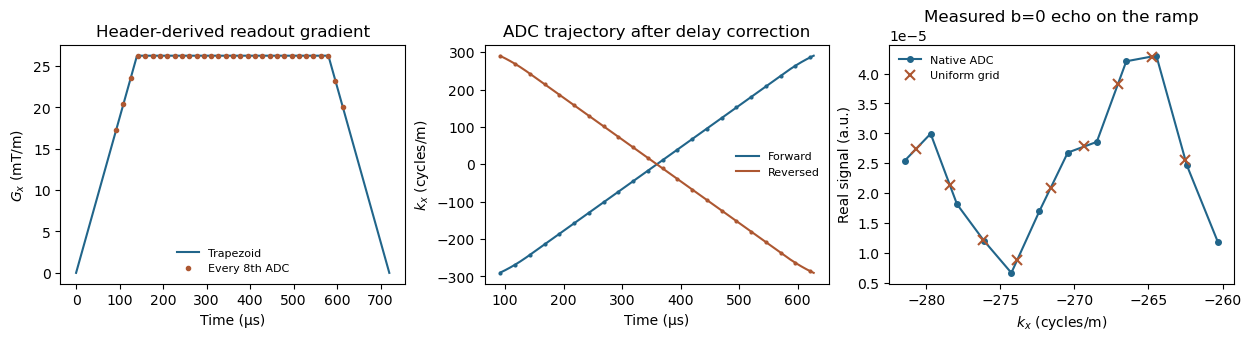

In [13]:
echo = 32  # Forward echo at the phase-encode center
adc = brain['im_adc'][0, echo]
polarity = brain['im_pol'][0, echo]
native, kx = scanner.native_correct(adc, polarity, geom, readout_fit)
uniform_line = scanner.linear_regrid(kx, native, geom.target)
scanner.show_trajectory(geom, readout_fit, native, kx, uniform_line)

- **Apply the readout calibration.** Correct both imaging volumes with the baseline fit. The separate calibration acquisition has its own navigator fit.
- **Parallel imaging reconstruction.** After ramp sampling correction and removal of readout oversampling, GRAPPA uses the calibration data to estimate the skipped odd lines. BART transforms each coil’s k-space to an image and combines the coil magnitudes by root-sum-of-squares. [Griswold et al., 2002](https://doi.org/10.1002/mrm.10171)
- **Compare diffusion contrast.** Use the first two panels to compare magnitude on a common scale. The last panel uses a narrower window so that the higher-b anatomy is easier to see.

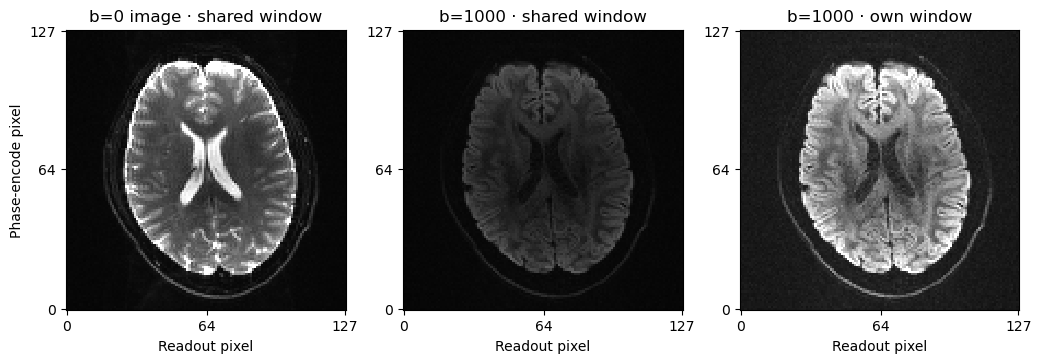

In [14]:
brain_cartesian, brain_acs = scanner.correct_and_regrid(brain, geom, readout_fit)
brain_images = scanner.reconstruct_r2(brain_cartesian, brain_acs)
scanner.show_brain_images(brain_images)

### What changes when one reconstruction step is missing?

- **Full-band reference.** Use all the acquired even lines and reconstruct the intervening odd lines by parallel imaging. This reference spans the original phase-encode range.
- **Withhold an edge.** Keep the measured even lines through index 96. The upper edge is now missing, and every interior gap is bracketed by measured lines. Reconstruct the same retained band for each image below.
- **Combined reconstruction.** Use the separate multicoil calibration data to estimate the interior lines by GRAPPA. Apply homodyne partial Fourier reconstruction to each coil and volume, then combine the coil magnitudes.

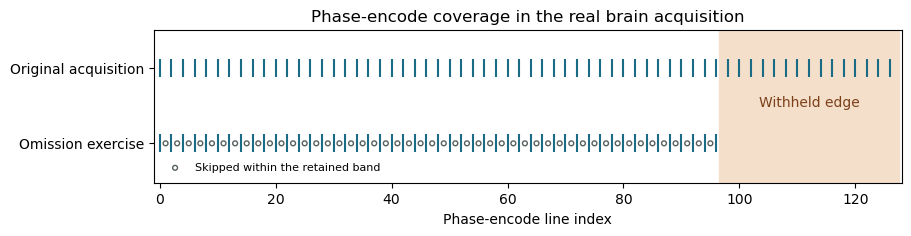

In [15]:
import brain_steps as steps

retained = np.arange(int(brain['nky'])) <= 96
steps.show_measured_band(brain['im_ky'][0], retained)
plt.show()

measured_band = steps.keep_band(brain_cartesian, retained)
grappa_band = steps.grappa_in_band(measured_band, brain_acs, retained)
combined = steps.partial_fourier_rss(grappa_band, retained)

Read across one b-value at a time. All panels in a row share the same grayscale window. Each omission changes one operation in the combined reconstruction.

| Step omitted | What happens to the retained echoes? |
|---|---|
| Nyquist ghost correction | Use zero delay and zero even–odd phase error. |
| Ramp sampling correction | Treat the native readout samples as uniformly spaced. Keep the polarity and fitted readout timing. |
| Parallel imaging reconstruction | The interior gaps remain empty. Partial Fourier reconstruction operates on folded coil images. |
| Partial Fourier reconstruction | Fill the interior lines by parallel imaging and leave the edge at zero. |

For either readout omission, apply the same processing to the imaging and calibration echoes. Compare each magnitude image with the full-band reference using NRMSE.

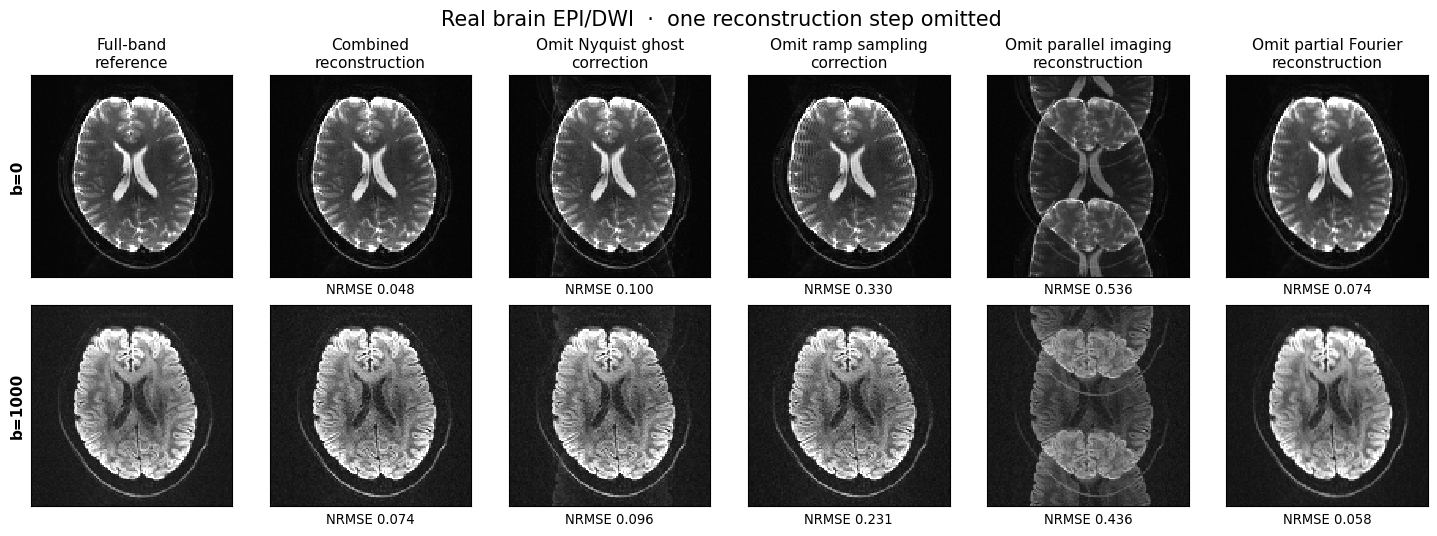

In [16]:
omitted = steps.omit_one_step(brain, geom, readout_fit, retained, measured_band, grappa_band)
steps.show_omissions(brain_images, combined, omitted, brain['b_values'])
plt.show()

**Where does each omission change the image?** The difference maps use the combined reconstruction as their reference. Look outside the head for displaced anatomy and along the brain boundary for changes in the readout spacing. For the missing edge, use the full-band errors in the preceding figure. Homodyne gives the smaller error at $b=0$ on this slice, whereas zero filling gives the smaller error at $b=1000$.

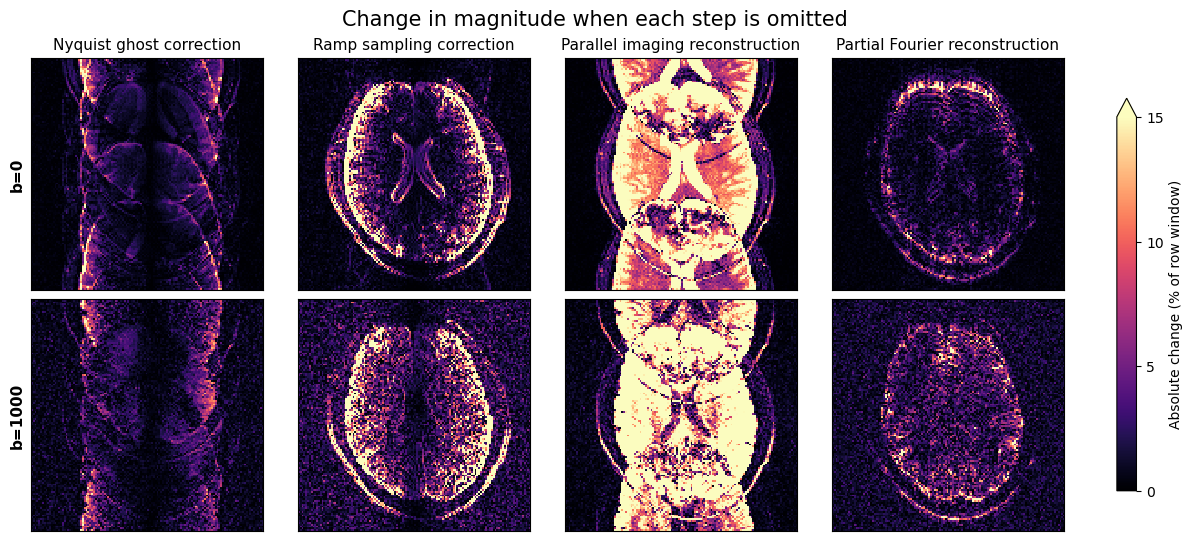

In [17]:
steps.show_changes(brain_images, combined, omitted, brain['b_values'])
plt.show()

## 4 · Unfold individual diffusion shots with parallel imaging reconstruction

- In this extension, the same phantom is sampled with two complementary shots and eight receive coils. Each shot has its own image phase.
- Estimate coil sensitivities from the multicoil b=0 calibration with BART `ecalib`. Use `pics` and the same maps to unfold each shot separately.
- Combine the reconstructed magnitudes across **shots**. Two equally bright shot images give a root-sum-of-squares magnitude $\sqrt{2}$ times the single-shot magnitude. The combined panel uses a correspondingly larger display window.

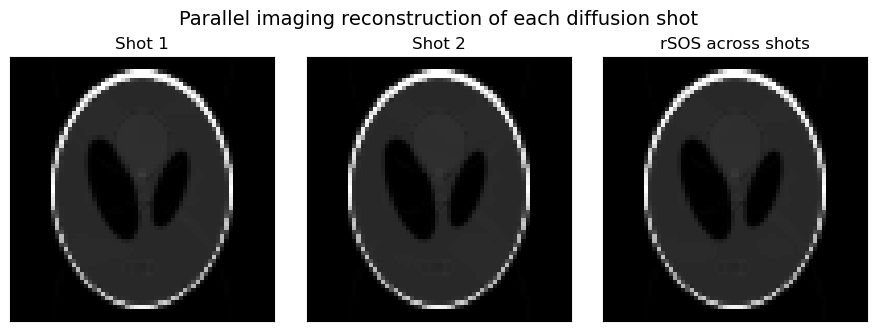

In [18]:
calibration, shot_kspace = scan['ms_b0_calib'], scan['ms_shots']
maps = bart(['ecalib', '-m', '1', '-r', '36', '-k', '6', '-t', '0.005', '-c', '0.1'], calibration)
solver = ['pics', '-l2', '-r', '0.0001', '-i', '60', '-S']
shots = [bart(solver, k, maps).squeeze() for k in shot_kspace]
shot_rsos = np.sqrt(np.sum(np.abs(shots)**2, axis=0))
plots.show_shots(shots, shot_rsos)

### Worked example · An off-isocenter spin echo

- The five-slice sequence selects slices with frequency offsets on its excitation and refocusing RF pulses. It also sets the phases of those pulses. The receiver offsets are zero. Follow the `SLC` labels to put the acquired order **0, 2, 4, 1, 3** into spatial order.
- Compare two KomaMRI simulations of a stationary point at the **same slice position**. Use the imaging echoes after refocusing. Keep the slice-selective frequencies active in both. Toggle only the position-dependent RF phase adjustments. For an ideal spin echo, the predicted rotation is $\Delta\theta_\mathrm{echo}=2\Delta\phi_{180}-\Delta\phi_{90}$, modulo a full turn. [Hennig, 1991](https://doi.org/10.1002/cmr.1820030302) · [Castillo-Passi et al., 2023](https://doi.org/10.1002/mrm.29635)
- Measure that rotation from the complex echoes, $\arg(S_\mathrm{on}S_\mathrm{off}^*)$. A common rotation of all imaging lines multiplies the complex image by one factor $e^{i\Delta\theta}$ and preserves its magnitude.

At +1 mm: rotation -120.0°, magnitude ratio 1.000


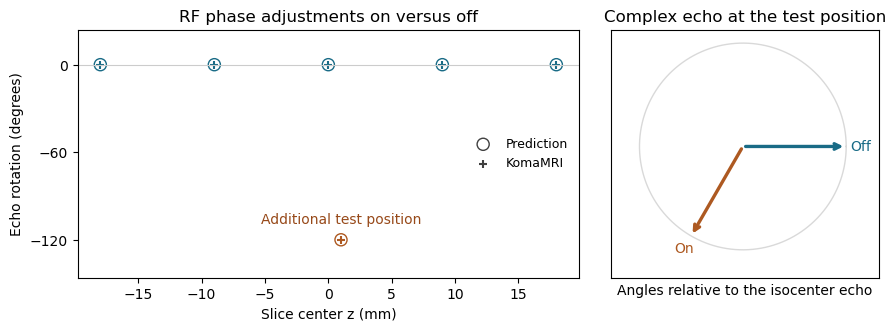

In [19]:
echo_check = np.genfromtxt('data/offcenter_echo.csv', delimiter=',', names=True, dtype=None, encoding='utf-8')
test = echo_check[echo_check['case'] == 'shifted'][0]
on  = test['on_real']  + 1j * test['on_imag']
off = test['off_real'] + 1j * test['off_imag']
print(f'At +1 mm: rotation {np.angle(on * off.conjugate(), deg=True):.1f}°, magnitude ratio {abs(on / off):.3f}')
plots.show_slice_phase(echo_check)
plt.show()

At the five prescribed slice centers, the predicted rotations wrap to nearly zero. The largest simulated change is 0.006° or less. For the additional **+1 mm** test at the same pulse timings, the prediction and the simulated rotation are both **−120.0°**. The echo magnitude ratio is 1.000, and forward and reverse imaging echoes rotate together. Magnitude reconstruction needs no extra correction in this example. To compare complex images across slices at the added position, a single slice-wise rotation can bring the echo to the isocenter phase reference.

### Optional · Estimate the apparent diffusion coefficient

- The two sequence groups have different echo times. Each has its own b=0 measurement and diffusion weightings along x and y. In a single tissue compartment, $S(b,\mathrm{TE},d)=S_0(\mathrm{TE})e^{-bD_d}$.
- Reconstruct all 26 volumes. Each TE group uses its own baseline readout calibration, and POCS uses each volume’s own image phase. Select **one echo time and one direction** and measure mean magnitude in a fixed region. Fit $\ln S=\ln S_0(\mathrm{TE})-bD_d$. The negative slope is the directional apparent diffusion coefficient (ADC), in mm²/s. [Stejskal & Tanner, 1965](https://doi.org/10.1063/1.1695690)
- Compare the slopes in the marked compartment with its prescribed diffusivities. The two b=0 images also let you see what happens if you normalize a higher-b image using a baseline at another echo time.

x-direction ADC at TE 46.7 ms: 0.000744 mm²/s


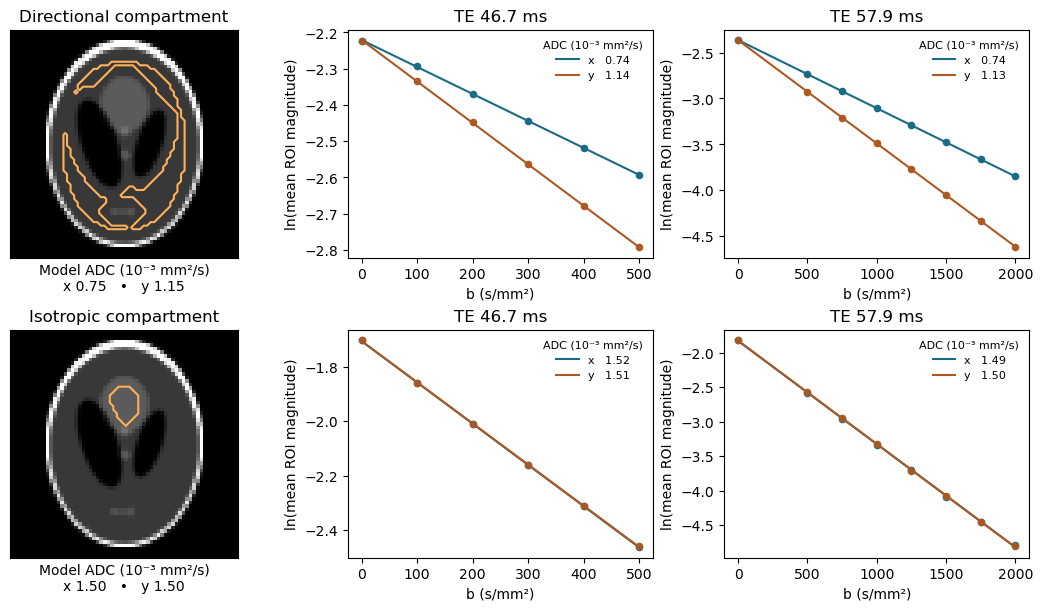

In [20]:
b, te, direction = scan['series_b'], scan['series_te_ms'], scan['series_direction']
regions = [scan['adc_roi'], scan['adc_iso_roi']]
baseline_fits, signals = sequence.reconstruct_adc_rois(scan, regions)
signal = signals[0]                              # compartment with directional diffusion
sel = np.isclose(te, 46.7) & ((direction == 'x') | (b == 0))
slope, intercept = np.polyfit(b[sel], np.log(signal[sel]), 1)
print(f'x-direction ADC at TE 46.7 ms: {-slope:.6f} mm²/s')
sequence.show_adc(scan, signals)
plt.show()

**What changes if the baseline or direction is mixed up?** At b=500, a longer TE also reduces the signal through transverse relaxation. Use $-\ln(S_{500}/S_0)/500$ twice with the same numerator. Compare the pooled slope with the separate x and y slopes in the directional compartment. In the isotropic compartment, the two fitted slopes nearly coincide.

In [21]:
def roi_value(b_value, echo_time, encoding):
    pick = (b == b_value) & np.isclose(te, echo_time) & (direction == encoding)
    return signal[pick].item()

s500 = roi_value(500, 57.9, 'x')
for baseline_te in (57.9, 46.7):
    ratio = s500 / roi_value(0, baseline_te, 'baseline')
    print(f'b=500 at TE 57.9 ms / baseline at {baseline_te} ms: {ratio:.3f}   ADC {-np.log(ratio)/500:.6f} mm²/s')

pooled = np.isclose(te, 46.7)
slope, _ = np.polyfit(b[pooled], np.log(signal[pooled]), 1)
print(f'Pooling x and y at 46.7 ms gives one ADC: {-slope:.6f} mm²/s')

b=500 at TE 57.9 ms / baseline at 57.9 ms: 0.691   ADC 0.000740 mm²/s
b=500 at TE 57.9 ms / baseline at 46.7 ms: 0.600   ADC 0.001020 mm²/s
Pooling x and y at 46.7 ms gives one ADC: 0.000946 mm²/s


### Optional · Estimate the readout error from measured navigators

The public Siemens `epi.dat` acquisition contains one imaging volume, two receive coils, and three unencoded navigator echoes in reverse–forward–reverse order. Average the outer pair and compare it with the middle navigator to estimate the delay and even–odd phase error. Apply the fit to the imaging echoes. How does the signal inside the marked corner change on a common display scale? [Original twixtools acquisition](https://github.com/pehses/twixtools/blob/2d7c8774fdea486e81365a1a872e48dbd156aaff/example_data/epi.dat)

Delay -0.25 µs, even–odd phase error +0.097 rad


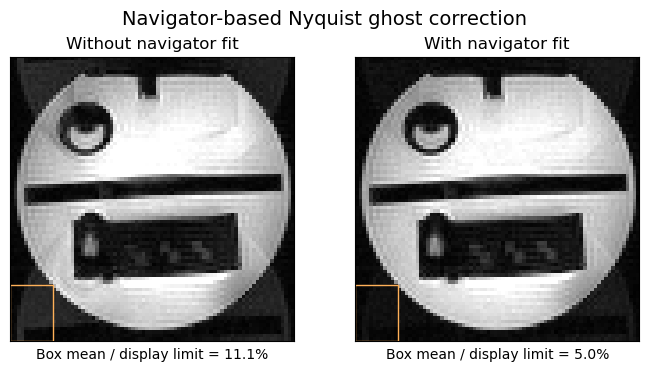

In [22]:
public_epi = epi.load_epi_dat('data/epi.dat')
nav_delay, nav_error = epi.fit_navigators(public_epi)
print(f'Delay {nav_delay:+.2f} µs, even–odd phase error {nav_error:+.3f} rad')
plots.show_siemens(epi.siemens_image(public_epi, 0, 0), epi.siemens_image(public_epi, nav_delay, nav_error))

### Bring your KomaMRI echoes

For the single-slice files, select slice 0. The exporter uses the sequence labels to select the imaging profiles and pairs their complex samples with the ADC times and physical coordinates. It also saves the readout waveform for ramp sampling correction. [KomaMRI sequence API](https://juliahealth.org/KomaMRI.jl/stable/reference/2-koma-base)

```julia
include("preparation/export_koma.jl")
export_koma_epi("ref_export", seq_ref, raw_ref; b_value=0, slice=0)
export_koma_epi("dw_export",  seq_dw,  raw_dw;  b_value=500, slice=0)
```

Pack the two exports together. The loader checks that their readout grid, polarities and ADC dwell times agree.

```sh
python preparation/generate_acquisitions.py --koma-pair ref_export dw_export --pair-output my_epi.npz
```

```python
scan = epi.load_arrays("my_epi.npz")
baseline, diffusion = scan["raw"]
kx_grid = epi.cartesian_kx(scan)
ky, ny = scan["ky_idx"], int(scan["matrix_xy"][1])
delay, error = epi.fit_b0(baseline, scan)
kx = epi.adc_trajectory(scan, delay)
raw = epi.correct_native(diffusion, scan["pol"], error)
k = epi.regrid(raw, kx, kx_grid, ky, ny)
image = bart(["homodyne", "-C", "1", str(len(ky) / ny)], k)
plt.imshow(np.abs(image).T, origin="lower", cmap="gray")
plt.show()
```

This example displays the higher-b image. Use the baseline echoes in the same reconstruction to display the b=0 image. The original workshop sequences are in [the Pulseq archive](preparation/seq_diffusion.zip).

## References and further reading

### EPI readout and Nyquist ghosts

- Bruder H, Fischer H, Reinfelder HE, Schmitt F. Image reconstruction for echo planar imaging with nonequidistant k-space sampling. *Magnetic Resonance in Medicine*. 1992, 23(2), 311–323. [DOI](https://doi.org/10.1002/mrm.1910230211)
- Reeder SB, Atalar E, Bolster BD Jr, McVeigh ER. Quantification and reduction of ghosting artifacts in interleaved echo-planar imaging. *Magnetic Resonance in Medicine*. 1997, 38(3), 429–439. [DOI](https://doi.org/10.1002/mrm.1910380312)
- Heid O. Robust EPI phase correction. *Proceedings of the 5th Annual Meeting of ISMRM*, Vancouver, 1997, p. 2014. [Proceedings volume, pp. 2001–2050](https://doi.org/10.1002/mrmp.22419970141)
- Skare S, Clayton DB, Newbould R, Moseley M, Bammer R. A fast and robust minimum entropy based non-interactive Nyquist ghost correction algorithm. *Proceedings of the 14th Annual Meeting of ISMRM*, Seattle, 2006, abstract 2349. [ISMRM archive](https://archive.ismrm.org/2006/2349.html) · [Proceedings PDF](https://cds.ismrm.org/protected/06MProceedings/PDFfiles/02349.pdf)
- Nordell A, Bammer R, Skare S. Major Speed-Up of Nyquist Ghost Correction in ramp-sampled EPI. *Proceedings of the 15th Annual Meeting of ISMRM*, Berlin, 2007, abstract 1833. Figure 3 shows how delaying the gradient before integration changes the sampling path used for gridding. [Proceedings PDF](https://cds.ismrm.org/protected/07MProceedings/PDFfiles/01833.pdf)
- McKay JA, Moeller S, Zhang L, Auerbach EJ, Nelson MT, Bolan PJ. Nyquist ghost correction of breast diffusion weighted imaging using referenceless methods. *Magnetic Resonance in Medicine*. 2019, 81(4), 2624–2631. [DOI](https://doi.org/10.1002/mrm.27563)
- Chu ML, Chang HC, Chung HW, Truong TK, Bashir MR, Chen NK. POCS-based reconstruction of multiplexed sensitivity encoded MRI (POCSMUSE): a general algorithm for reducing motion-related artifacts. *Magnetic Resonance in Medicine*. 2015, 74(5), 1336–1348. See the baseline odd/even calibration in the diffusion EPI experiment. [DOI](https://doi.org/10.1002/mrm.25527)

### Partial Fourier

- Feinberg DA, Hale JD, Watts JC, Kaufman L, Mark A. Halving MR imaging time by conjugation: demonstration at 3.5 kG. *Radiology*. 1986, 161(2), 527–531. [DOI](https://doi.org/10.1148/radiology.161.2.3763926)
- Cuppen J, van Est A. Reducing MR imaging time by one-sided reconstruction. *Magnetic Resonance Imaging*. 1987, 5(6), 526–527. [DOI](https://doi.org/10.1016/0730-725X%2887%2990402-4)
- MacFall JR, Pelc NJ, Vavrek RM. Correction of spatially dependent phase shifts for partial Fourier imaging. *Magnetic Resonance Imaging*. 1988, 6(2), 143–155. [DOI](https://doi.org/10.1016/0730-725X%2888%2990444-4)
- Noll DC, Nishimura DG, Macovski A. Homodyne detection in magnetic resonance imaging. *IEEE Transactions on Medical Imaging*. 1991, 10(2), 154–163. [DOI](https://doi.org/10.1109/42.79473)
- Haacke EM et al. A fast, iterative, partial-Fourier technique capable of local phase recovery. *Journal of Magnetic Resonance*. 1991, 92(1), 126–145. [DOI](https://doi.org/10.1016/0022-2364%2891%2990253-P)
- McGibney G, Smith MR, Nichols ST, Crawley A. Quantitative evaluation of several partial Fourier reconstruction algorithms used in MRI. *Magnetic Resonance in Medicine*. 1993, 30(1), 51–59. [DOI](https://doi.org/10.1002/mrm.1910300109)

### Diffusion, spin echoes and simulation

- Stejskal EO, Tanner JE. Spin diffusion measurements: spin echoes in the presence of a time-dependent field gradient. *Journal of Chemical Physics*. 1965, 42, 288–292. [DOI](https://doi.org/10.1063/1.1695690)
- Hennig J. Echoes—how to generate, recognize, use or avoid them in MR-imaging sequences. Part I: Fundamental and not so fundamental properties of spin echoes. *Concepts in Magnetic Resonance*. 1991, 3, 125–143. [DOI](https://doi.org/10.1002/cmr.1820030302)

### Parallel imaging, multishot DWI and simulation

- Pruessmann KP, Weiger M, Scheidegger MB, Boesiger P. SENSE: sensitivity encoding for fast MRI. *Magnetic Resonance in Medicine*. 1999, 42(5), 952–962. [PubMed](https://pubmed.ncbi.nlm.nih.gov/10542355/)
- Griswold MA et al. Generalized autocalibrating partially parallel acquisitions (GRAPPA). *Magnetic Resonance in Medicine*. 2002, 47(6), 1202–1210. [DOI](https://doi.org/10.1002/mrm.10171)
- Skare S et al. Clinical multishot DW-EPI through parallel imaging with considerations of susceptibility, motion, and noise. *Magnetic Resonance in Medicine*. 2007, 57(5), 881–890. [DOI](https://doi.org/10.1002/mrm.21176)
- Uecker M et al. ESPIRiT—an eigenvalue approach to autocalibrating parallel MRI: where SENSE meets GRAPPA. *Magnetic Resonance in Medicine*. 2014, 71(3), 990–1001. [DOI](https://doi.org/10.1002/mrm.24751)
- Castillo-Passi C et al. KomaMRI.jl: an open-source framework for general MRI simulations with GPU acceleration. *Magnetic Resonance in Medicine*. 2023, 90(1), 329–342. [DOI](https://doi.org/10.1002/mrm.29635)

## Acknowledgment

Allen D. Elster’s *Questions and Answers in MRI* provides illustrated explanations of the acquisition and reconstruction principles used here.

- Trace an EPI echo through its readout gradient. [Echo-planar imaging](https://mriquestions.com/echo-planar-imaging.html) · [The k-space grid](https://mriquestions.com/k-space-grid.html)
- Locate the displaced copy on a diffusion image. [DWI pulse sequence](https://mriquestions.com/making-a-dw-image.html) · [Nyquist ghosts](https://mriquestions.com/nyquist-n2-ghosts.html)
- Relate the central phase estimate to the missing edge of k-space. [Partial Fourier techniques](https://mriquestions.com/partial-fourier.html) · [Phase-encode partial Fourier](https://mriquestions.com/phase-symmetry.html)
- See how calibration lines and receive coils supply missing interleaves. [GRAPPA and ARC](https://mriquestions.com/grappaarc.html)